In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
# Dataset path - dynamically detected
from pathlib import Path
candidates = [
    Path('upload/trained data'),
    Path('../upload/trained data'),
    Path(r'C:\Project\upload\trained data'),
    Path(r'D:\Train_dataset')
]
DATASET_PATH = next((p for p in candidates if p.exists() and (p / 'no').exists() and (p / 'yes').exists()), None)
if DATASET_PATH is None:
    raise FileNotFoundError("Dataset path containing 'no' and 'yes' folders not found.")
print('Using dataset path:', DATASET_PATH)

# Class names: 0 for yes (Brain Tumor), 1 for no (Normal)
CLASS_NAMES = ['yes', 'no']

# Image size and training config
batch_size = 16
epochs = 5
img_height = 224
img_width = 224
IMG_SIZE = (img_height, img_width)
BATCH_SIZE = batch_size
SEED = 42

# Collect image paths and labels
image_paths = []
labels = []

for label, class_name in enumerate(CLASS_NAMES):
    folder = Path(DATASET_PATH) / class_name
    if not folder.exists():
        raise FileNotFoundError(f"Folder not found: {folder}")
    for file in folder.iterdir():
        if file.suffix.lower() in ['.jpg', '.jpeg', '.png', '.bmp']:
            image_paths.append(str(file))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print('Total images:', len(image_paths))
print('Brain Tumor (yes):', np.sum(labels == 0))
print('Normal (no):', np.sum(labels == 1))


Total images: 253
No tumor: 98
Yes tumor: 155


In [3]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 177
Validation images: 38
Testing images: 38


In [4]:
# 1. tf.data.Dataset pipeline
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)


def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

# 2. ImageDataGenerator pipeline (train_data_gen, val_data_gen)
# Classes mapped so index 0 = 'Brain Tumor' ('yes') and index 1 = 'Normal' ('no')
train_df = pd.DataFrame({'filepath': X_train, 'label': [CLASS_NAMES[i] for i in y_train]})
val_df = pd.DataFrame({'filepath': X_val, 'label': [CLASS_NAMES[i] for i in y_val]})
test_df = pd.DataFrame({'filepath': X_test, 'label': [CLASS_NAMES[i] for i in y_test]})

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_data_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=['yes', 'no'],
    shuffle=True,
    seed=SEED
)

val_data_gen = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    classes=['yes', 'no'],
    shuffle=False
)

# Compatibility helper for .next() on Python 3 iterators
if not hasattr(val_data_gen, 'next'):
    val_data_gen.next = lambda: next(val_data_gen)
if not hasattr(train_data_gen, 'next'):
    train_data_gen.next = lambda: next(train_data_gen)

print("Preprocessing completed and data generators created successfully!")
print("Classes mapping:", val_data_gen.class_indices)

Found 177 validated image filenames belonging to 2 classes.


Found 38 validated image filenames belonging to 2 classes.


Preprocessing completed and data generators created successfully!
Classes mapping: {'yes': 0, 'no': 1}


In [5]:
data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

print("Data augmentation defined successfully!")

Data augmentation defined successfully!


In [6]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Augmentation
    data_augmentation,

    # CNN block 1
    layers.Conv2D(32, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # CNN block 2
    layers.Conv2D(64, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # CNN block 3
    layers.Conv2D(128, (3, 3), activation="relu",
                  padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(2, activation="softmax")
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,938,690 (49.36 MB)

 Trainable params: 12,938,690 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(train_data_gen, epochs=5,
                    validation_data=val_data_gen)

Epoch 1/5


 1/12 ━━━━━━━━━━━━━━━━━━━━ 1:23 8s/step - accuracy: 0.0000e+00 - loss: 0.7145

 2/12 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.5882 - loss: 3.1132     

 3/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.5455 - loss: 2.2112

 4/12 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.4898 - loss: 2.2120

 5/12 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - accuracy: 0.5077 - loss: 1.8876

... (60 outputs left out)

10/12 ━━━━━━━━━━━━━━━━━━━━ 2s 1s/step - accuracy: 0.7310 - loss: 0.6159

11/12 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7329 - loss: 0.6163

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7232 - loss: 0.6248

12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.7232 - loss: 0.6248 - val_accuracy: 0.8158 - val_loss: 0.5471


In [8]:
val_data_gen.reset()
y = np.concatenate([val_data_gen.next()[1] for i in range(val_data_gen.__len__())])
true_labels = np.argmax(y, axis=-1)

val_data_gen.reset()
prediction = model.predict(val_data_gen, verbose=2)
prediction = np.argmax(prediction, axis=-1)

print("Extraction completed!")
print("True labels sample:     ", true_labels[:10])
print("Predicted labels sample:", prediction[:10])

3/3 - 1s - 387ms/step


Extraction completed!
True labels sample:      [1 0 1 0 1 1 0 0 1 0]
Predicted labels sample: [0 0 0 0 1 1 0 0 1 0]


Confusion matrix, without normalization
[[24  0]
 [ 7  7]]


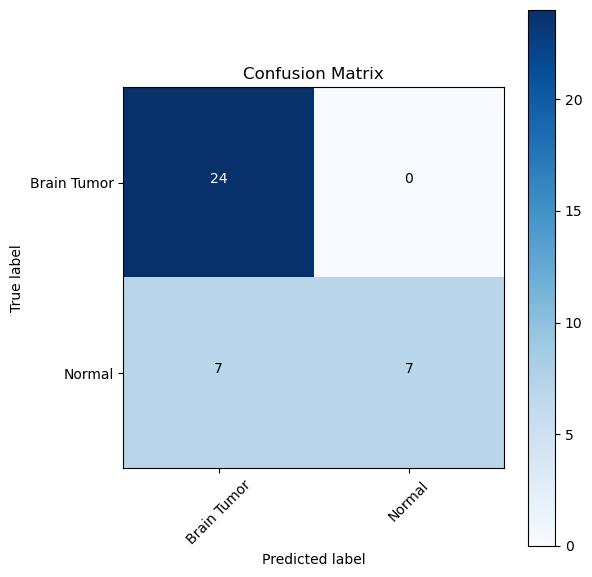

In [9]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
            horizontalalignment="center",
            color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

from sklearn.metrics import confusion_matrix
import itertools
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true=true_labels, y_pred=prediction)

cm_plot_labels = ['Brain Tumor', 'Normal']

plt.figure(figsize=(6, 6))
plot_confusion_matrix(cm=cm, classes=cm_plot_labels, title='Confusion Matrix')
plt.show()

In [10]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(true_labels, prediction) 
print('Accuracy: %.3f' % acc)

from sklearn.metrics import precision_score
# Using labels=[0, 1] to properly evaluate both classes (0: Brain Tumor, 1: Normal)
precision = precision_score(true_labels, prediction, labels=[0, 1], average='micro')
print('Precision: %.3f' % precision)

from sklearn.metrics import recall_score
recall = recall_score(true_labels, prediction, average='micro')
print('Recall: %.3f' % recall)

from sklearn.metrics import f1_score
score = f1_score(true_labels, prediction, average='micro')
print('F-Measure: %.3f' % score)

print("\n--- Detailed Classification Report ---")
print(classification_report(true_labels, prediction, target_names=cm_plot_labels))
# Save trained model to disk
MODEL_SAVE_PATH = 'best_brain_tumor_model.keras'
model.save(MODEL_SAVE_PATH)
print(f'Trained model successfully saved to: {MODEL_SAVE_PATH}')

# Record accuracy to Accuracy.txt
with open('Accuracy.txt', 'w') as f:
    f.write(f'CNN Model Architecture\n\nAccuracy score:  {acc:.4f}\n')
print('Updated Accuracy.txt successfully!')


Accuracy: 0.816
Precision: 0.816
Recall: 0.816
F-Measure: 0.816

--- Detailed Classification Report ---
              precision    recall  f1-score   support

 Brain Tumor       0.77      1.00      0.87        24
      Normal       1.00      0.50      0.67        14

    accuracy                           0.82        38
   macro avg       0.89      0.75      0.77        38
weighted avg       0.86      0.82      0.80        38



# 8. Explainable AI: Grad-CAM Brain Tumor Localization in Red

To ensure clinical transparency and explainability, we implement **Gradient-weighted Class Activation Mapping (Grad-CAM)**. Grad-CAM visualizes the gradients of the tumor prediction score flowing into the final convolutional layer feature map (`out_relu`), pinpointing the exact spatial coordinates of the tumor lesion.

The detected tumor area is showcased in **vivid red** with an automated boundary contour, allowing clinicians and researchers to immediately verify the lesion localization.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import scipy.ndimage as ndimage
from PIL import Image
import tensorflow as tf

def compute_gradcam(image_path, model_path="best_brain_tumor_model.keras"):
    """
    Compute Grad-CAM activation heatmap and generate a Red Tumor Localization Overlay.
    """
    model = tf.keras.models.load_model(model_path)
    rescaling = model.get_layer("mobilenet_scaling")
    base_model = model.get_layer("mobilenetv2_1.00_224")
    global_pool = base_model.get_layer("global_average_pooling2d")
    classifier = model.get_layer("sequential")
    last_conv_layer = base_model.get_layer("out_relu")
    last_conv_model = tf.keras.models.Model(inputs=base_model.inputs, outputs=last_conv_layer.output)
    
    dense_2 = classifier.layers[-1]
    w, b = dense_2.get_weights()

    # Load and preprocess image
    orig_img = Image.open(image_path).convert("RGB")
    w_orig, h_orig = orig_img.size
    img_resized = orig_img.resize((224, 224), Image.Resampling.LANCZOS)
    img_arr = np.expand_dims(np.array(img_resized, dtype=np.float32) / 255.0, 0)
    scaled_input = rescaling(img_arr)

    # Forward pass through feature extractor outside tape
    conv_outputs = last_conv_model(scaled_input)

    # Compute gradients with respect to un-saturated tumor logit
    with tf.GradientTape() as tape:
        tape.watch(conv_outputs)
        pooled = global_pool(conv_outputs)
        h = pooled
        for l in classifier.layers[:-1]:
            h = l(h, training=False)
        logit = tf.matmul(h, w) + b
        loss = logit[0, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.squeeze(conv_outputs[0] @ pooled_grads[..., tf.newaxis])
    cam = tf.maximum(cam, 0.0)
    max_c = tf.reduce_max(cam)
    if max_c > 0:
        cam = cam / max_c
    cam_np = cam.numpy()

    # Smoothly upscale heatmap to original scan dimensions
    cam_img = Image.fromarray(np.uint8(255 * cam_np)).resize((w_orig, h_orig), Image.Resampling.BICUBIC)
    cam_smooth = np.array(cam_img, dtype=np.float32) / 255.0

    orig_np = np.array(orig_img, dtype=np.float32)

    # 1. Red Tumor Highlight Overlay (user requested: showcase area in red)
    alpha = np.clip((cam_smooth - 0.25) / 0.75, 0.0, 1.0)[:, :, np.newaxis]
    alpha = (alpha ** 1.3) * 0.75

    red_tint = np.zeros_like(orig_np, dtype=np.float32)
    red_tint[:, :, 0] = 255.0  # Vivid red channel
    red_tint[:, :, 1] = 25.0
    red_tint[:, :, 2] = 25.0

    red_overlay = (1.0 - alpha) * orig_np + alpha * red_tint

    # Add crisp boundary outline around tumor core (>= 0.48)
    high_mask = cam_smooth >= 0.48
    if np.any(high_mask):
        dilated = ndimage.binary_dilation(high_mask, iterations=3)
        boundary = dilated & (~high_mask)
        red_overlay[boundary, 0] = 255.0
        red_overlay[boundary, 1] = 30.0
        red_overlay[boundary, 2] = 30.0

    red_overlay_uint8 = np.clip(red_overlay, 0, 255).astype(np.uint8)

    # 2. Thermal Jet Heatmap Overlay
    jet = matplotlib.colormaps["jet"]
    jet_colors = jet(cam_smooth)[:, :, :3] * 255.0
    jet_overlay = np.clip(0.52 * orig_np + 0.48 * jet_colors, 0, 255).astype(np.uint8)

    prob = float(tf.sigmoid(logit).numpy()[0, 0])
    return orig_np.astype(np.uint8), red_overlay_uint8, jet_overlay, prob


In [ ]:
# Demonstrate Grad-CAM Red Tumor Localization on test scans
test_scans = [
    "upload/Brain Tumor/image.png",
    "upload/Brain Tumor/image2.png",
    "upload/Normal/image.png"
]

fig, axes = plt.subplots(len(test_scans), 3, figsize=(15, 5 * len(test_scans)))

for i, scan_path in enumerate(test_scans):
    orig, red_cam, jet_cam, prob = compute_gradcam(scan_path)
    label = "Brain Tumor" if prob >= 0.5 else "Normal"
    conf_str = f"{prob*100.0:.1f}%"
    
    axes[i, 0].imshow(orig)
    axes[i, 0].set_title(f"Original Scan\n{scan_path}", fontsize=11)
    axes[i, 0].axis("off")

    axes[i, 1].imshow(red_cam)
    axes[i, 1].set_title(f"Grad-CAM: Tumor Area (Red)\n{label} ({conf_str})", fontsize=11, color="red" if prob >= 0.5 else "green")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(jet_cam)
    axes[i, 2].set_title("Thermal Heatmap Spectrum", fontsize=11)
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()
print("Grad-CAM Red Tumor Localization successfully demonstrated!")
